# 01. Exploratory Data Analysis (EDA)
## Student Feedback Analysis using NLP (Aspect-Based Sentiment Analysis)

### Objective
This notebook performs exploratory analysis on the student feedback dataset:
1. Loading the raw wide spreadsheet (`student-data.xlsx`)
2. Inspecting column names, shapes, data types, missing values, and duplicates
3. Reshaping from WIDE to LONG aspect format
4. Analyzing class distributions (overall and per-aspect)
5. Examining comment length distributions across sentiment categories
6. Identifying frequent vocabulary and keywords


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
for p in [".", ".."]:
    abs_p = os.path.abspath(p)
    if os.path.exists(os.path.join(abs_p, "src")) and abs_p not in sys.path:
        sys.path.insert(0, abs_p)

from src.preprocess import clean_text

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


### 1. Load Raw Dataset & Diagnostics
The raw survey contains student ratings and open-ended feedback across 6 core aspects:
- `teaching` + `teachingl`
- `coursecontent` + `coursecontentl`
- `examination` + `examinationl`
- `labwork` + `labworkl`
- `library_facilities` + `library_facilitiesl`
- `extracurricular` + `extracurricularl`


In [2]:
# Locate dataset file dynamically
candidates = [
    "student-data.xlsx",
    "../student-data.xlsx",
    "data/raw/student-data.xlsx",
    "../data/raw/student-data.xlsx"
]
data_file = next(os.path.abspath(c) for c in candidates if os.path.exists(c))

df_raw = pd.read_excel(data_file)
print(f"Dataset File : {os.path.basename(data_file)}")
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print("\nDetected Columns:")
for c in df_raw.columns:
    print(f"  - '{c}' ({df_raw[c].dtype})")


Dataset File : student-data.xlsx
Dataset Shape: 222 rows, 12 columns

Detected Columns:
  - 'teachingl' (int64)
  - 'teaching' (object)
  - 'coursecontentl' (float64)
  - 'coursecontent' (object)
  - 'examinationl' (float64)
  - 'Examination' (object)
  - 'labworkl' (float64)
  - 'labwork' (object)
  - 'library_facilitiesl' (float64)
  - ' library_facilities' (object)
  - 'extracurricularl' (int64)
  - 'extracurricular' (object)


In [3]:
# Check missing values and duplicate records
print("Missing values per column:")
print(df_raw.isnull().sum())

print(f"\nDuplicate survey responses in raw data: {df_raw.duplicated().sum()}")
df_raw.head(3)


Missing values per column:
teachingl              0
teaching               0
coursecontentl         1
coursecontent          0
examinationl           3
Examination            2
labworkl               1
labwork                1
library_facilitiesl    3
 library_facilities    0
extracurricularl       0
extracurricular        0
dtype: int64

Duplicate survey responses in raw data: 10


,teachingl,teaching,coursecontentl,coursecontent,examinationl,Examination,labworkl,labwork,library_facilitiesl,library_facilities,extracurricularl,extracurricular
0,-1,there is no interaction between students and t...,-1.0,Only 2 / & sometime none out of 5 subjects are...,0.0,"No issue in it, just little bit of old fashioned",-1.0,Lab not taken properly in proper time.,-1.0,Book are not organisation properly in library,-1,Not proper equipment for extra co curricular a...
1,-1,Teaching is not upto the mark. They only focus...,-1.0,Vast and outdated.,0.0,Exam pattern and how it is conducted is really...,1.0,well and good infrastructure and have trending...,1.0,library is very well managed and provide neede...,1,This university is no1 in terms of extracurric...
2,-1,Teacher uses instructional strategies that are...,-1.0,Very bad and poor,-1.0,Not upto the mark.,-1.0,very small and not good equiment,-1.0,no proper selfs are there for books,-1,No extra curricular activities


### 2. Reshaping WIDE to LONG Format
To train aspect-based sentiment models, we reshape the wide dataset into a LONG table where each row corresponds to one `(student_id, aspect, text, label)`.
We also compute an `overall_sentiment` per student from their average aspect label:
- $\text{mean} \le -0.34 \rightarrow \text{negative}$
- $\text{mean} \ge 0.34 \rightarrow \text{positive}$
- $\text{otherwise} \rightarrow \text{neutral}$


In [4]:
# Locate processed data
long_cands = ["data/processed/feedback_long.csv", "../data/processed/feedback_long.csv"]
wide_cands = ["data/processed/feedback_wide.csv", "../data/processed/feedback_wide.csv"]

long_path = next(os.path.abspath(c) for c in long_cands if os.path.exists(c))
wide_path = next(os.path.abspath(c) for c in wide_cands if os.path.exists(c))

df_long = pd.read_csv(long_path)
df_wide = pd.read_csv(wide_path)

print(f"Long Format Rows (Feedback Instances): {len(df_long)}")
print(f"Wide Format Rows (Students)           : {len(df_wide)}")
df_long.sample(5, random_state=42)


Long Format Rows (Feedback Instances): 1324
Wide Format Rows (Students)           : 222


,student_id,aspect,text,label,sentiment
888,STU_0005,library_facilities,very bad,-1,negative
756,STU_0095,labwork,helps in improving skills,1,positive
1164,STU_0062,extracurricular,Good it provides a great platform,1,positive
554,STU_0113,examination,very poor,-1,negative
1055,STU_0173,library_facilities,Insufficient books,-1,negative


### 3. Overall Class Distribution
Let us examine the balance between Positive, Neutral, and Negative feedback comments across the entire dataset.


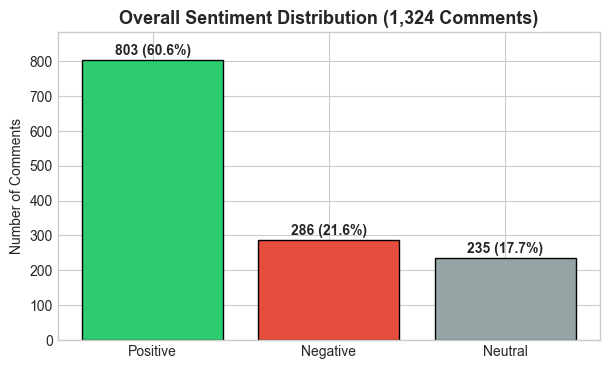

In [5]:
plt.figure(figsize=(7, 4))
colors = {"positive": "#2ecc71", "neutral": "#95a5a6", "negative": "#e74c3c"}
dist = df_long['sentiment'].value_counts()
pcts = df_long['sentiment'].value_counts(normalize=True) * 100

bars = plt.bar(dist.index.str.capitalize(), dist.values, color=[colors[c] for c in dist.index], edgecolor='black')
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df_long)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, h + 15, f"{h} ({pct:.1f}%)", ha='center', fontweight='bold')

plt.title("Overall Sentiment Distribution (1,324 Comments)", fontsize=13, fontweight='bold')
plt.ylabel("Number of Comments")
plt.ylim(0, max(dist.values) + 80)
plt.show()


### 4. Per-Aspect Class Distribution
Next, we evaluate how sentiment varies across each of the six academic aspects.


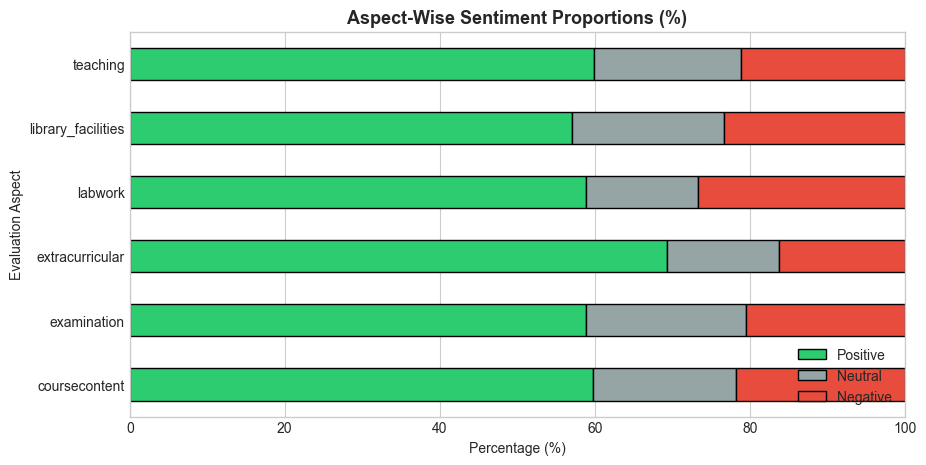

Percentage Breakdown per Aspect:


sentiment,positive,neutral,negative
aspect,,,
coursecontent,59.7,18.6,21.7
examination,58.9,20.5,20.5
extracurricular,69.4,14.4,16.2
labwork,58.8,14.5,26.7
library_facilities,57.1,19.6,23.3
teaching,59.9,18.9,21.2


In [6]:
crosstab = pd.crosstab(df_long['aspect'], df_long['sentiment'], normalize='index')[['positive', 'neutral', 'negative']] * 100

ax = crosstab.plot(kind='barh', stacked=True, color=['#2ecc71', '#95a5a6', '#e74c3c'], figsize=(10, 5), edgecolor='black')
plt.title("Aspect-Wise Sentiment Proportions (%)", fontsize=13, fontweight='bold')
plt.xlabel("Percentage (%)")
plt.ylabel("Evaluation Aspect")
plt.legend(["Positive", "Neutral", "Negative"], loc="lower right")
plt.xlim(0, 100)
plt.show()

print("Percentage Breakdown per Aspect:")
display(crosstab.round(1))


### 5. Comment Length Analysis by Sentiment
Are negative comments systematically longer than positive comments? Let us measure word and character lengths.


Length Summary by Sentiment Category:


word_count              char_count             
                mean median   std       mean median   std
sentiment                                                
negative        12.1    8.0  12.1       70.2   49.0  69.4
neutral         11.9   10.0  11.6       69.0   58.0  67.5
positive         4.7    2.0   6.3       27.1    9.0  38.4

C:\Users\hp\AppData\Local\Temp\ipykernel_14296\2233377407.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_long, x='sentiment', y='word_count', palette=['#2ecc71', '#95a5a6', '#e74c3c'], showmeans=True)


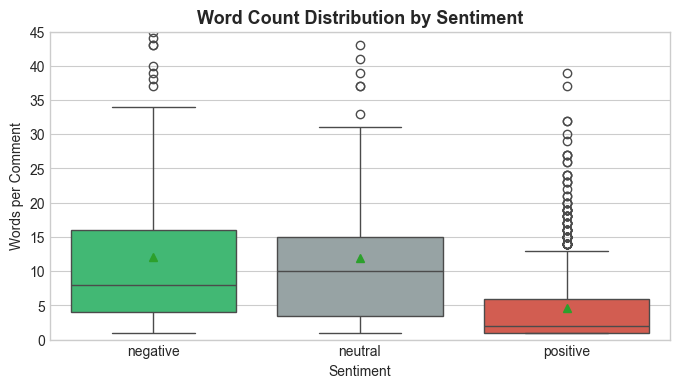

In [7]:
df_long['char_count'] = df_long['text'].astype(str).str.len()
df_long['word_count'] = df_long['text'].astype(str).str.split().str.len()

print("Length Summary by Sentiment Category:")
display(df_long.groupby('sentiment')[['word_count', 'char_count']].agg(['mean', 'median', 'std']).round(1))

plt.figure(figsize=(8, 4))
sns.boxplot(data=df_long, x='sentiment', y='word_count', palette=['#2ecc71', '#95a5a6', '#e74c3c'], showmeans=True)
plt.title("Word Count Distribution by Sentiment", fontsize=13, fontweight='bold')
plt.xlabel("Sentiment")
plt.ylabel("Words per Comment")
plt.ylim(0, 45)
plt.show()


### 6. Student-Level Overall Sentiment
Distribution of overall student sentiment computed from their aspect score average:


In [8]:
stu_dist = df_wide['overall_sentiment'].value_counts()
print("Student-Level Sentiment Distribution:")
for s, c in stu_dist.items():
    print(f"  {s.capitalize():<10}: {c} students ({c/len(df_wide)*100:.1f}%)")


Student-Level Sentiment Distribution:
  Positive  : 128 students (57.7%)
  Neutral   : 65 students (29.3%)
  Negative  : 29 students (13.1%)
